# Cadi, rialzati, cammina
## Insegnare a camminare a un robot umanoide con il reinforcement learning

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StefanoCapezzone/cadi-rialzati-cammina/blob/main/notebook/cadi_rialzati_cammina_tutorial_eseguito.ipynb)

*Tutorial del talk di Stefano Capezzone al **Linux Day 2026** (Roma2LUG, Università di Roma Tor Vergata, 24 ottobre 2026).*

In questo notebook addestriamo da zero una **rete neurale che fa camminare un Unitree G1**, un robot umanoide vero (1,32 m, ~35 kg, 29 articolazioni), dentro un simulatore fisico open source. Nessuno spiega al robot *come* si cammina: prova, cade, riceve un premio quando fa la cosa giusta e una penalità quando sbaglia. Milioni di volte.

Alla fine avrai:
- una rete addestrata da te, con le curve di apprendimento;
- i video del robot che cammina, curva e va di lato a comando;
- il confronto tra il robot appena nato e quello addestrato;
- i pesi della rete, anche in formato numpy, da usare fuori da questo notebook.

Tutto il software è libero: **MuJoCo** (fisica), **MuJoCo Warp** (fisica su GPU), **JAX** (calcolo), **Brax** (l'algoritmo PPO) e **MuJoCo Playground** (l'ambiente del G1), sviluppati in gran parte da Google DeepMind. L'unica cosa che noleggiamo è la GPU di Google Colab.

> **Questa è la versione già eseguita** (A100, 24 ottobre 2026: 203 milioni di passi in 40 minuti). Per addestrare la tua rete apri invece la [versione pulita](https://colab.research.google.com/github/StefanoCapezzone/cadi-rialzati-cammina/blob/main/notebook/cadi_rialzati_cammina_tutorial.ipynb) ed esegui le celle dall'alto in basso.
>
> **Come si usa:** esegui le celle dall'alto in basso (Maiusc+Invio). Le celle di testo spiegano cosa sta per succedere; le celle di codice sono commentate riga per riga.

### Indice
0. Prima di cominciare: GPU, tempi e costi
1. Installazione
2. Dove salvare i risultati
3. Il protagonista: il G1 nel simulatore
4. Cosa vede e cosa comanda la rete
5. La ricompensa: le regole del gioco
6. Un robot senza cervello
7. Come impara: PPO in breve
8. Gli iperparametri
9. **L'addestramento**
10. Le curve di apprendimento
11. Il robot addestrato cammina
12. Com'è cambiato durante l'addestramento
13. Portare la rete fuori da JAX (numpy puro)
14. Esperimenti da provare
15. Per approfondire

## 0. Prima di cominciare: GPU, tempi e costi

Il simulatore fa camminare **migliaia di robot in parallelo sulla GPU**: per questo serve un runtime con GPU.
In Colab: **Runtime → Cambia tipo di runtime → Acceleratore hardware**.

| Modalità | GPU | Passi di simulazione | Tempo indicativo | Cosa ottieni |
|---|---|---|---|---|
| `prova` | qualsiasi, anche CPU | 2.000 | pochi minuti | solo la verifica che tutto funzioni |
| `veloce` | **T4** (gratuita) | 50 milioni | ~35 minuti + ~15 per i video | il robot smette quasi di cadere e comincia a camminare |
| `completo` | **A100**, L4, H100 (Colab Pro o a consumo) | 200 milioni | ~40 minuti su A100 + ~5 per i video | la rete "di DeepMind": cammina, curva, va di lato, regge le spinte |

**Tempi misurati con questo notebook (24 ottobre 2026):** su **A100** 203 milioni di passi in **40 minuti** (ricompensa finale 14,6, episodi lunghi in media 772 passi su 1000); su **T4** 50 milioni di passi in **34 minuti** (ricompensa 2,5, episodi di 457 passi: il robot cammina ancora incerto). A settembre la stessa run su A100 aveva richiesto 124 minuti, circa 14 unità di calcolo Colab (~1,60 € a consumo): i tempi dipendono dalla macchina che Colab ti assegna e dalle versioni dei driver. La prima riga di avanzamento ti dice subito a che velocità vai.

La modalità viene scelta da sola in base alla GPU che trovi; puoi cambiarla nella cella qui sotto.

In [1]:
# Che GPU abbiamo? (nvidia-smi esiste solo se il runtime ha una GPU NVIDIA)
import subprocess
try:
    GPU = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    GPU = ""
print("GPU:", GPU or "nessuna (runtime CPU)")

# Scelta automatica della modalità (puoi forzarla scrivendo per esempio MODALITA = "veloce")
if not GPU:
    MODALITA = "prova"
elif "T4" in GPU:
    MODALITA = "veloce"
else:
    MODALITA = "completo"
print("Modalità:", MODALITA)

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB
Modalità: completo


## 1. Installazione

Installiamo **le stesse versioni che abbiamo usato noi** (bloccate: con versioni diverse i risultati possono cambiare o il codice può non funzionare):

| pacchetto | versione | a cosa serve |
|---|---|---|
| `playground` | 0.2.0 | gli ambienti di locomozione, G1 compreso |
| `jax`, `jaxlib` (CUDA 12) | 0.9.2 | calcolo su GPU, differenziazione automatica |
| `flax` | 0.12.6 | le reti neurali |
| `mediapy` | — | mostrare i video nel notebook |

Brax (PPO), MuJoCo e MuJoCo Warp arrivano come dipendenze di `playground`.

> **Nota (ottobre 2026):** Colab ha preinstallata una versione di JAX per CUDA 13. Va disinstallata, altrimenti due "plugin" CUDA entrano in conflitto (`ALREADY_EXISTS: PJRT_Api already exists for device type cuda`). Lo fa l'ultima riga della cella.
>
> Ci vogliono 1-2 minuti. **Esegui questa cella prima di qualsiasi `import jax`**: se hai già importato JAX, riavvia la sessione (Runtime → Riavvia sessione) e ricomincia da qui.

In [2]:
%%capture log_installazione
!pip install -U "playground==0.2.0" "jax[cuda12]==0.9.2" "jaxlib==0.9.2" "flax==0.12.6" mediapy
!pip uninstall -y jax-cuda13-plugin jax-cuda13-pjrt

In [3]:
import os
# Impostazioni da dare PRIMA di importare JAX e MuJoCo:
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"   # il notebook usa la GPU solo quanto serve:
                                                        # il grosso lo userà l'addestramento
os.environ["MUJOCO_GL"] = "egl" if GPU else "osmesa"   # rendering dei video senza schermo
if not GPU:
    os.environ["PYOPENGL_PLATFORM"] = "osmesa"

import jax, jax.numpy as jp, numpy as np
import mujoco, mediapy as media
import warp
warp.config.quiet = True    # niente messaggi di compilazione di MuJoCo Warp
from mujoco_playground import registry
import importlib.metadata as md_
print("JAX", jax.__version__, "su", jax.devices())
print("MuJoCo", mujoco.__version__, "· playground", md_.version("playground"), "· brax", md_.version("brax"))
IMPL = "warp" if GPU else "jax"   # motore fisico: MuJoCo Warp su GPU, MJX (JAX) su CPU

JAX 0.9.2 su [CudaDevice(id=0)]
MuJoCo 3.17.0 · playground 0.2.0 · brax 0.14.2


## 2. Dove salvare i risultati

I file di un runtime Colab spariscono quando la sessione si chiude. Se vuoi tenere pesi e curve, salvali su **Google Drive** (`USA_DRIVE = True`): Colab ti chiederà l'autorizzazione.

Struttura della cartella dei risultati:
```
g1_tutorial/
├── progress.csv          una riga per valutazione: passi, ricompensa, durata degli episodi, minuti
├── network_config.json   com'è fatta la rete
└── fasi/
    ├── step_000000000000.pkl / .npz   la rete appena nata (pesi casuali)
    ├── step_0000xxxxxxxx.pkl / .npz   ...una "fotografia" a ogni valutazione...
    └── step_final.pkl / .npz          la rete finale
```

In [4]:
USA_DRIVE = False   # True = salva su Google Drive, in MyDrive/g1_tutorial

if USA_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/g1_tutorial"
else:
    OUT = os.path.abspath("g1_tutorial")
os.makedirs(OUT, exist_ok=True)
print("Risultati in:", OUT)

Risultati in: /content/g1_tutorial


## 3. Il protagonista: il G1 nel simulatore

MuJoCo Playground contiene il **gemello digitale del G1**: masse, inerzie, motori e limiti delle articolazioni presi dal modello ufficiale (MuJoCo Menagerie). L'ambiente si chiama `G1JoystickFlatTerrain`: un G1 su un pavimento piatto, che deve seguire un comando "da joystick" (vai avanti, di lato, gira).

Al primo utilizzo Playground scarica il modello del robot (qualche secondo).

In [5]:
AMBIENTE = "G1JoystickFlatTerrain"
cfg = registry.get_default_config(AMBIENTE)
cfg.impl = IMPL
cfg.naconmax = 64                      # spazio per i contatti: qui simuliamo un robot alla volta
cfg.noise_config.level = 0.0           # niente rumore sui sensori e...
cfg.push_config.enable = False         # ...niente spinte: per guardare il robot vogliamo calma
env = registry.load(AMBIENTE, config=cfg)

m = env.mj_model
print(f"Gradi di libertà: {m.nv} (6 del corpo libero nello spazio + {m.nu} articolazioni motorizzate)")
print(f"Passo della fisica: {env.sim_dt*1000:.0f} ms · passo di controllo della rete: {env.dt*1000:.0f} ms "
      f"({1/env.dt:.0f} decisioni al secondo)")
print(f"Durata di un episodio: {cfg.episode_length} passi = {cfg.episode_length*env.dt:.0f} s")
print("Le articolazioni, nell'ordine in cui la rete le comanda:")
for i in range(m.nu):
    print(f"  {i:2d} {m.actuator(i).name}")

mujoco_menagerie not found. Downloading...


Checking out commit 1b86ece576591213e2b666ebf59508454200ca97
Successfully downloaded mujoco_menagerie
Gradi di libertà: 35 (6 del corpo libero nello spazio + 29 articolazioni motorizzate)
Passo della fisica: 2 ms · passo di controllo della rete: 20 ms (50 decisioni al secondo)
Durata di un episodio: 1000 passi = 20 s
Le articolazioni, nell'ordine in cui la rete le comanda:
   0 left_hip_pitch_joint
   1 left_hip_roll_joint
   2 left_hip_yaw_joint
   3 left_knee_joint
   4 left_ankle_pitch_joint
   5 left_ankle_roll_joint
   6 right_hip_pitch_joint
   7 right_hip_roll_joint
   8 right_hip_yaw_joint
   9 right_knee_joint
  10 right_ankle_pitch_joint
  11 right_ankle_roll_joint
  12 waist_yaw_joint
  13 waist_roll_joint
  14 waist_pitch_joint
  15 left_shoulder_pitch_joint
  16 left_shoulder_roll_joint
  17 left_shoulder_yaw_joint
  18 left_elbow_joint
  19 left_wrist_roll_joint
  20 left_wrist_pitch_joint
  21 left_wrist_yaw_joint
  22 right_shoulder_pitch_joint
  23 right_shoulder_roll_

""

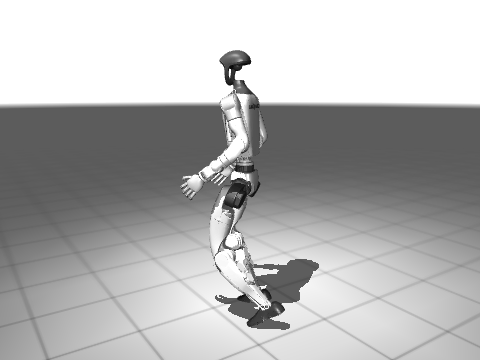

In [6]:
# Una fotografia del robot alla partenza: la posa di riferimento (ginocchia piegate) con gli angoli
# dei giunti variati un po' a caso. Ogni episodio parte in modo diverso: anche questo aiuta a generalizzare.
stato = env.reset(jax.random.PRNGKey(0))
foto = env.render([stato], height=360, width=480, camera="track")[0]
media.show_image(foto)

## 4. Cosa vede e cosa comanda la rete

Il controllo del robot è **a due livelli**:

```
 comando "vai avanti a 0,5 m/s"
            │
            ▼
 ┌──────────────────────┐   50 volte al secondo     ┌─────────────────────────┐   500 volte al secondo
 │  RETE NEURALE        │ ─────────────────────────►│ CONTROLLO DEI GIUNTI    │──► motori ──► robot
 │  103 numeri → 29     │  29 posizioni obiettivo   │ (PD: insegue l'angolo)  │
 └──────────────────────┘                           └─────────────────────────┘
            ▲                                                                          │
            └──────────────────── sensori: inclinazione, rotazione, angoli ◄───────────┘
```

**Cosa entra nella rete (osservazione `state`, 103 numeri):**

| pezzo | quanti | significato |
|---|---|---|
| velocità del bacino | 3 | quanto va veloce, nel riferimento del robot |
| giroscopio | 3 | quanto sta ruotando |
| gravità | 3 | da che parte è il "giù": dice quanto è inclinato |
| comando | 3 | velocità avanti, di lato e di rotazione richieste |
| angoli dei giunti | 29 | rispetto alla posa di riferimento |
| velocità dei giunti | 29 | |
| ultima azione | 29 | cosa ha deciso al passo precedente |
| fase del passo | 4 | un "metronomo" (seno e coseno) per ciascun piede |

In addestramento ai sensori si aggiunge del **rumore**, come in un robot vero.

**Cosa esce:** 29 numeri tra -1 e 1, uno per articolazione. La posizione obiettivo di ogni giunto è `posa di riferimento + 0,5 × azione` (radianti).

Il **critico** (la seconda rete, usata solo durante l'addestramento) vede di più: 216 numeri "privilegiati", tra cui i valori senza rumore, le forze dei motori e i contatti dei piedi. Sul robot vero ci va solo la prima rete.

In [7]:
print("Osservazioni:", {k: v for k, v in env.observation_size.items()})
print("Azioni:", env.action_size)
oss = stato.obs["state"]
nomi = ["velocità bacino"]*3 + ["giroscopio"]*3 + ["gravità"]*3 + ["comando"]*3 + \
       ["angoli giunti"]*29 + ["velocità giunti"]*29 + ["ultima azione"]*29 + ["fase del passo"]*4
print(f"\nIl vettore 'state' alla partenza ({len(nomi)} numeri), primi 12:")
for n, v in list(zip(nomi, np.asarray(oss)))[:12]:
    print(f"  {n:16s} {v:+.3f}")

Osservazioni: {'privileged_state': (216,), 'state': (103,)}
Azioni: 29

Il vettore 'state' alla partenza (103 numeri), primi 12:
  velocità bacino  +0.377
  velocità bacino  -0.336
  velocità bacino  +0.455
  giroscopio       -0.163
  giroscopio       -0.030
  giroscopio       -0.165
  gravità          +0.000
  gravità          +0.000
  gravità          -1.000
  comando          +0.233
  comando          +0.046
  comando          -0.317


## 5. La ricompensa: le regole del gioco

La ricompensa è **l'unico modo per dire al robot cosa vogliamo**. È una somma pesata di tanti termini, calcolata a ogni passo. I pesi positivi sono premi, quelli negativi penalità. Questi sono i pesi scelti da DeepMind per il G1 (non li abbiamo toccati):

In [8]:
import pandas as pd
spiegazioni = {
    "tracking_lin_vel": "seguire la velocità richiesta", "tracking_ang_vel": "seguire la rotazione richiesta",
    "feet_air_time": "tenere i piedi in aria (passi veri, non strisciati)", "feet_phase": "piedi a tempo col metronomo",
    "termination": "cadere (l'episodio finisce)", "orientation": "busto inclinato",
    "stand_still": "muoversi quando il comando è 'fermo'", "dof_pos_limits": "giunti a fine corsa",
    "feet_slip": "piedi che scivolano", "joint_deviation_hip": "anche lontane dalla posa",
    "ang_vel_xy": "oscillazioni del busto", "joint_deviation_knee": "ginocchia lontane dalla posa",
    "pose": "tutto il corpo lontano dalla posa", "collision": "autocollisioni (piede contro gamba...)",
    "contact_force": "colpi troppo forti a terra",
}
pesi = {k: v for k, v in cfg.reward_config.scales.items() if v != 0}
tab = pd.DataFrame([(k, v, spiegazioni.get(k, "")) for k, v in pesi.items()],
                   columns=["termine", "peso", "significato"]).sort_values("peso", ascending=False)
tab.style.hide(axis="index")

termine,peso,significato
feet_air_time,2.000000,"tenere i piedi in aria (passi veri, non strisciati)"
feet_phase,1.000000,piedi a tempo col metronomo
tracking_lin_vel,1.000000,seguire la velocità richiesta
tracking_ang_vel,0.750000,seguire la rotazione richiesta
contact_force,-0.010000,colpi troppo forti a terra
collision,-0.100000,autocollisioni (piede contro gamba...)
joint_deviation_knee,-0.100000,ginocchia lontane dalla posa
pose,-0.100000,tutto il corpo lontano dalla posa
ang_vel_xy,-0.150000,oscillazioni del busto
joint_deviation_hip,-0.250000,anche lontane dalla posa


Nota il peso enorme della caduta (−100): finire a terra è la cosa peggiore che possa succedere. Ma attenzione: **il robot ottimizza quello che chiedi, non quello che intendi**. Se i pesi sono sbilanciati trova scorciatoie impreviste (*reward hacking*): nel nostro esperimento per insegnargli a rialzarsi, premiato per "alzare il busto", ha imparato a sdraiarsi sui gomiti.

Durante l'addestramento il mondo viene anche reso **imprevedibile** (*domain randomization*), così la rete impara a cavarsela in condizioni diverse da quelle del simulatore:

| cosa cambia | quanto |
|---|---|
| attrito piedi–pavimento | 0,4 – 1,0 |
| attrito interno dei giunti | × 0,9 – 1,1 |
| masse dei segmenti | × 0,9 – 1,1, busto ± 1 kg |
| posa di zero dei giunti | ± 0,05 rad |
| spinte | ogni 5–10 s, fino a 2 m/s |
| comandi | casuali ogni 10 s: avanti ± 1 m/s, di lato ± 0,5 m/s, rotazione ± 1 rad/s |

## 6. Un robot senza cervello

Prima di addestrare, guardiamo cosa succede **senza una rete che decide**:
1. **motori fermi**: ogni giunto tiene la posa di partenza, come una statua;
2. **azioni a caso**: è più o meno quello che fa una rete appena nata, con i pesi casuali.

Quando il robot cade l'episodio finisce e ricomincia da capo: nel video vedi i tentativi uno dopo l'altro. Stare in piedi **non è uno stato, è un processo**: se nessuno corregge continuamente, si cade.

*(Il rendering dei video è la parte lenta: qualche decina di secondi.)*

In [9]:
SALTA = 2   # mostriamo un fotogramma ogni 2 passi di controllo: video a 25 fotogrammi al secondo

def gira(politica, comandi, seme=0):
    # Simula il robot seguendo una lista di comandi [avanti, lato, rotazione], uno per passo da 20 ms.
    # politica(oss, chiave) -> azione. Se il robot cade, riparte da capo (come in addestramento).
    # Teniamo solo le posizioni (qpos) di ogni passo: bastano per disegnare e occupano poca memoria.
    comandi = jp.asarray(comandi)
    def un_passo(carry, cmd):
        stato, chiave = carry
        stato = stato.replace(info={**stato.info, "command": cmd})
        chiave, k1, k2 = jax.random.split(chiave, 3)
        nuovo = env.step(stato, politica(stato.obs, k1))
        ripartenza = env.reset(k2)
        nuovo = jax.tree.map(lambda a, b: jp.where(nuovo.done > 0, a, b), ripartenza, nuovo)
        return (nuovo, chiave), nuovo.data.qpos
    @jax.jit
    def tutto(chiave):
        s0 = env.reset(chiave)
        _, qpos = jax.lax.scan(un_passo, (s0, jax.random.PRNGKey(seme + 7)), comandi)
        return qpos
    qpos = np.asarray(tutto(jax.random.PRNGKey(seme)))
    jax.clear_caches()   # libera la memoria della simulazione compilata: ogni video ne compila una nuova
    return disegna(qpos[SALTA - 1::SALTA])

def disegna(qpos, altezza=360, larghezza=480):
    # Disegna una sequenza di pose con il renderer di MuJoCo, inquadrando con la telecamera "track"
    d = mujoco.MjData(m)
    with mujoco.Renderer(m, height=altezza, width=larghezza) as r:
        fotogrammi = []
        for q in qpos:
            d.qpos[:] = q
            mujoco.mj_forward(m, d)
            r.update_scene(d, camera="track")
            fotogrammi.append(r.render())
    return fotogrammi

def percorso(tratti):
    # [(secondi, [avanti m/s, lato m/s, rotazione rad/s]), ...] -> un comando per ogni passo
    return np.concatenate([np.tile(c, (int(round(s / env.dt)), 1)) for s, c in tratti]).astype(np.float32)

fermo = percorso([(6.0, [0.0, 0.0, 0.0])])
statua = lambda oss, k: jp.zeros(env.action_size)
a_caso = lambda oss, k: jax.random.uniform(k, (env.action_size,), minval=-1, maxval=1)
media.show_videos({"motori fermi": gira(statua, fermo), "azioni a caso": gira(a_caso, fermo)},
                  fps=1 / (env.dt * SALTA), height=270)

motori fermi This browser does not support the video tag.,azioni a caso This browser does not support the video tag.


## 7. Come impara: PPO in breve

Usiamo **PPO** (*Proximal Policy Optimization*, Schulman et al. 2017), l'algoritmo più usato per la locomozione in simulazione. Un giro di addestramento:

```
 ┌─► 1. RACCOGLI   8.192 robot giocano 20 passi ciascuno con la rete di adesso
 │                 → 163.840 esempi (osservazione, azione, ricompensa)
 │       │
 │       ▼
 │   2. GIUDICA    il critico stima quanto vale ogni situazione; il "vantaggio" dice
 │                 se un'azione è andata meglio o peggio del previsto (GAE)
 │       │
 │       ▼
 │   3. AGGIORNA   4 passate sui dati in 32 blocchi: 128 piccoli passi di Adam;
 │                 il "clip" impedisce alla rete di cambiare troppo in un colpo
 │       │
 │       ▼
 └── 4. RIPETI     si buttano i dati e si riparte con la rete nuova (on-policy)
```

Le formule, per chi vuole il dettaglio:

$$\rho_t = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\text{old}}(a_t\mid s_t)} \qquad
L^{\text{clip}} = \mathbb{E}_t\Big[\min\big(\rho_t \hat A_t,\ \text{clip}(\rho_t, 1-\varepsilon, 1+\varepsilon)\,\hat A_t\big)\Big]$$

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t) \qquad \hat A_t = \sum_{l\ge 0} (\gamma\lambda)^l\,\delta_{t+l}$$

$$L = -L^{\text{clip}} + c_v\,\big(V - V^{\text{target}}\big)^2 - c_e\,\mathrm{H}[\pi_\theta]$$

- $\rho_t$: quanto la rete nuova rende più (o meno) probabile l'azione rispetto a quella che ha raccolto i dati;
- $\hat A_t$: il vantaggio (positivo = meglio del previsto), stimato con GAE;
- il **clip** con $\varepsilon = 0{,}2$ rende inutile spingere $\rho_t$ oltre $[0{,}8;\,1{,}2]$: aggiornamenti piccoli e stabili ("proximal");
- $\mathrm{H}$ è l'entropia: un piccolo premio per restare curiosi ed esplorare.

**Le reti:** l'attore è un MLP 103 → 512 → 256 → 128 → 58 (29 medie + 29 deviazioni standard di una distribuzione gaussiana schiacciata da una `tanh`), circa 225.000 parametri; il critico è un MLP 216 → 512 → 256 → 128 → 1.

## 8. Gli iperparametri

Usiamo **senza modifiche** gli iperparametri pubblicati da DeepMind per questo ambiente. Cambiamo solo quanti passi fare e quante volte fermarci a misurare (e a salvare una "fotografia" della rete).

In [10]:
from mujoco_playground.config import locomotion_params
ppo_cfg = locomotion_params.brax_ppo_config(AMBIENTE, IMPL)

PROFILI = {   # passi di simulazione, numero di valutazioni (= fasi salvate)
    "prova":    dict(passi=None,        valutazioni=2),
    "veloce":   dict(passi=50_000_000,  valutazioni=11),
    "completo": dict(passi=200_000_000, valutazioni=21),
}
PASSI = PROFILI[MODALITA]["passi"] or ppo_cfg.num_timesteps
VALUTAZIONI = PROFILI[MODALITA]["valutazioni"]

righe = [
    ("passi di simulazione", f"{PASSI:,}" if MODALITA != "prova" else "2.000 (prova)"),
    ("robot in parallelo", ppo_cfg.num_envs),
    ("passi per robot a ogni giro (rollout)", ppo_cfg.unroll_length),
    ("minibatch × dimensione", f"{ppo_cfg.num_minibatches} × {ppo_cfg.batch_size}"),
    ("passate sui dati per giro", ppo_cfg.num_updates_per_batch),
    ("learning rate (Adam)", ppo_cfg.learning_rate),
    ("sconto γ", ppo_cfg.discounting),
    ("clip ε", ppo_cfg.clipping_epsilon),
    ("peso dell'entropia", ppo_cfg.entropy_cost),
    ("clip del gradiente", ppo_cfg.max_grad_norm),
    ("rete attore", ppo_cfg.network_factory.policy_hidden_layer_sizes),
    ("rete critico", ppo_cfg.network_factory.value_hidden_layer_sizes),
]
pd.DataFrame(righe, columns=["iperparametro", "valore"]).style.hide(axis="index")

iperparametro,valore
passi di simulazione,"200,000,000"
robot in parallelo,8192
passi per robot a ogni giro (rollout),20
minibatch × dimensione,32 × 256
passate sui dati per giro,4
learning rate (Adam),0.000300
sconto γ,0.970000
clip ε,0.200000
peso dell'entropia,0.005000
clip del gradiente,1.000000


Un conto per farsi un'idea: con 200 milioni di passi da 20 ms, il robot accumula **circa 46 giorni di esperienza**, compressi in circa 40 minuti di A100 grazie ai robot in parallelo. Un robot vero, nello stesso tempo, si sarebbe rotto molte volte.

## 9. L'addestramento

Il codice dell'addestramento sta in un piccolo script, `addestra_g1.py`, che scriviamo nella cella qui sotto e poi lanciamo come **processo separato**: così, quando finisce, libera tutta la memoria della GPU e il notebook può poi fare i video senza problemi.

Leggilo: sono una sessantina di righe utili. I tre ingredienti sono l'**ambiente** (`registry.load`), la **domain randomization** (`get_domain_randomizer`) e **PPO di Brax** (`ppo.train`), più due funzioni nostre: `progresso` (scrive una riga a ogni valutazione) e `salva` (salva i pesi).

In [11]:
%%writefile addestra_g1.py
"""Addestra l'Unitree G1 a camminare con PPO (MuJoCo Playground + Brax).

  python addestra_g1.py --out /content/g1_tutorial --passi 200000000 --valutazioni 21
  python addestra_g1.py --out /tmp/prova --prova --impl jax       # prova lampo (anche su CPU)
  python addestra_g1.py --out ... --set reward_config.scales.feet_air_time=0   # esperimenti

Scrive nella cartella --out:
  progress.csv          una riga per valutazione: passi, ricompensa, durata episodio, minuti
  network_config.json   come e' fatta la rete (serve per ricaricarla)
  fasi/step_*.pkl       i pesi a ogni valutazione (formato Brax: normalizzatore, attore, critico)
  fasi/step_*.npz       gli stessi pesi in numpy puro (per usarli senza JAX)
"""
import argparse, ast, csv, functools, json, os, pickle, time

import jax
import numpy as np
from brax.training.agents.ppo import networks as ppo_networks
from brax.training.agents.ppo import train as ppo
from mujoco_playground import registry, wrapper
from mujoco_playground.config import locomotion_params

AMBIENTE = "G1JoystickFlatTerrain"   # G1 su pavimento piatto, comandato come con un joystick

p = argparse.ArgumentParser()
p.add_argument("--out", required=True, help="cartella dei risultati")
p.add_argument("--passi", type=int, default=None, help="passi di simulazione (default DeepMind: 200M)")
p.add_argument("--valutazioni", type=int, default=21, help="quante volte misurare e salvare la rete")
p.add_argument("--impl", default="warp", choices=["warp", "jax"],
               help="motore fisico su GPU: warp (MuJoCo Warp, veloce) o jax (MJX, va anche su CPU)")
p.add_argument("--num_envs", type=int, default=None, help="robot simulati in parallelo (default 8192)")
p.add_argument("--seme", type=int, default=1)
p.add_argument("--no_dr", action="store_true", help="senza domain randomization")
p.add_argument("--set", nargs="*", default=[], metavar="CHIAVE=VALORE",
               help="modifica la configurazione dell'ambiente, es. reward_config.scales.pose=-1.0")
p.add_argument("--prova", action="store_true", help="prova lampo: pochi robot e pochi passi")
args = p.parse_args()

# ---------------------------------------------------------------------------------------------
# 1. L'ambiente: il G1 nel simulatore, con le regole del gioco (osservazioni, azioni, ricompensa)
# ---------------------------------------------------------------------------------------------
env_cfg = registry.get_default_config(AMBIENTE)
env_cfg.impl = args.impl
for kv in args.set:                       # es. reward_config.scales.feet_air_time=0
  chiave, valore = kv.split("=", 1)
  try:
    valore = ast.literal_eval(valore)
  except (ValueError, SyntaxError):
    pass
  *percorso, ultima = chiave.split(".")
  obj = env_cfg
  for parte in percorso:
    obj = obj[parte]
  obj[ultima] = valore
  print(f"[cfg] {chiave} = {valore}", flush=True)
if args.prova:
  env_cfg.naconmax = 8 * 8              # memoria per i contatti: bastano pochi robot

env = registry.load(AMBIENTE, config=env_cfg)        # ambiente per imparare
eval_env = registry.load(AMBIENTE, config=env_cfg)   # ambiente per le valutazioni
# Domain randomization: ogni robot ha attriti, masse e posa leggermente diversi
randomizer = None if args.no_dr else registry.get_domain_randomizer(AMBIENTE)

# ---------------------------------------------------------------------------------------------
# 2. PPO con gli iperparametri pubblicati da DeepMind per questo ambiente
# ---------------------------------------------------------------------------------------------
ppo_params = locomotion_params.brax_ppo_config(AMBIENTE, args.impl)
if args.passi:
  ppo_params.num_timesteps = args.passi
if args.num_envs:
  ppo_params.num_envs = args.num_envs
ppo_params.num_evals = args.valutazioni
if args.prova:
  ppo_params.update(num_timesteps=2000, num_evals=2, num_envs=8, batch_size=8,
                    num_minibatches=2, unroll_length=5, num_updates_per_batch=1)

os.makedirs(f"{args.out}/fasi", exist_ok=True)
t0 = time.monotonic()
log = open(f"{args.out}/progress.csv", "w", newline="")
logw = csv.writer(log)
logw.writerow(["step", "eval_reward", "eval_episode_length", "minutes"])


def progresso(step, metrics):
  """Chiamata da Brax dopo ogni valutazione: scrive una riga e la stampa."""
  r = float(metrics.get("eval/episode_reward", np.nan))
  L = float(metrics.get("eval/avg_episode_length", np.nan))
  m = (time.monotonic() - t0) / 60
  logw.writerow([step, r, L, round(m, 2)]); log.flush()
  print(f"[{m:6.1f} min] passi {step:>12,}  ricompensa {r:7.2f}  durata episodio {L:5.0f}/1000",
        flush=True)


def salva(nome, params):
  """Salva i pesi in due formati: .pkl (Brax/JAX) e .npz (numpy puro)."""
  params = jax.device_get(params)
  with open(f"{args.out}/fasi/{nome}.pkl", "wb") as f:
    pickle.dump(params, f)
  piatto, _ = jax.tree_util.tree_flatten_with_path(params)
  np.savez(f"{args.out}/fasi/{nome}.npz",
           **{jax.tree_util.keystr(k): np.asarray(v) for k, v in piatto})


training_params = dict(ppo_params)
net_kwargs = dict(training_params.pop("network_factory", {}) or {})
num_eval_envs = 2 if args.prova else training_params.pop("num_eval_envs", 128)
training_params.pop("num_eval_envs", None)
network_factory = functools.partial(ppo_networks.make_ppo_networks, **net_kwargs)

with open(f"{args.out}/network_config.json", "w") as f:
  json.dump({"ambiente": AMBIENTE, "obs_size": {k: list(v) if isinstance(v, tuple) else v
                                                for k, v in dict(env.observation_size).items()},
             "action_size": env.action_size, "network_factory_kwargs": net_kwargs,
             "normalize_observations": bool(ppo_params.normalize_observations),
             "set": args.set}, f, indent=1, default=str)

print(f"[inizio] {ppo_params.num_timesteps:,} passi, {ppo_params.num_envs} robot in parallelo, "
      f"motore {args.impl}, dispositivo {jax.devices()[0].device_kind}", flush=True)

make_inference_fn, params, _ = ppo.train(
    environment=env, eval_env=eval_env,
    wrap_env_fn=wrapper.wrap_for_brax_training,
    randomization_fn=randomizer,
    network_factory=network_factory, num_eval_envs=num_eval_envs,
    seed=args.seme, progress_fn=progresso,
    policy_params_fn=lambda step, mk, prm: salva(f"step_{step:012d}", prm),
    **training_params)
salva("step_final", params)
print(f"Fatto in {(time.monotonic() - t0) / 60:.1f} minuti. Pesi in {args.out}/fasi", flush=True)

Writing addestra_g1.py


### Via!

Cosa aspettarsi:
- i primi **1-3 minuti** non succede nulla di visibile: JAX sta compilando la simulazione e la rete per la GPU;
- poi compare una riga a ogni valutazione: **passi**, **ricompensa** media e **durata degli episodi** (1000 = il robot non cade mai nei 20 secondi);
- all'inizio la ricompensa è negativa (circa −6) e gli episodi durano ~40 passi: il robot cade dopo un secondo;
- verso **30-50 milioni di passi** succede la cosa interessante: la durata degli episodi sale di colpo. Il robot ha capito come non cadere e comincia a camminare.

Se la sessione Colab si disconnette perdi l'output, ma con `USA_DRIVE = True` i file già salvati restano su Drive.

> Il filtro `grep` nasconde i messaggi tecnici di MuJoCo Warp (per esempio *iterations limit reached*, innocuo).

In [12]:
import time
inizio = time.time()
if MODALITA == "prova":
    !python -u addestra_g1.py --out "{OUT}" --prova --impl jax 2>&1 | grep --line-buffered -E "^\[|Fatto|Traceback|Error"
else:
    !python -u addestra_g1.py --out "{OUT}" --passi {PASSI} --valutazioni {VALUTAZIONI} --impl {IMPL} 2>&1 | grep --line-buffered -E "^\[|Fatto|Traceback|Error"
print(f"Tempo totale: {(time.time() - inizio) / 60:.1f} minuti")

[inizio] 200,000,000 passi, 8192 robot in parallelo, motore warp, dispositivo NVIDIA A100-SXM4-40GB
[   1.0 min] passi            0  ricompensa   -5.91  durata episodio    39/1000
[   4.1 min] passi   10,158,080  ricompensa   -2.78  durata episodio    54/1000
[   6.4 min] passi   20,316,160  ricompensa   -2.35  durata episodio    66/1000
[   8.4 min] passi   30,474,240  ricompensa   -1.90  durata episodio   108/1000
[  10.3 min] passi   40,632,320  ricompensa    0.22  durata episodio   333/1000
[  12.3 min] passi   50,790,400  ricompensa    1.51  durata episodio   442/1000
[  14.2 min] passi   60,948,480  ricompensa    4.47  durata episodio   517/1000
[  16.1 min] passi   71,106,560  ricompensa    5.37  durata episodio   529/1000
[  17.9 min] passi   81,264,640  ricompensa    6.93  durata episodio   591/1000
[  19.8 min] passi   91,422,720  ricompensa    8.19  durata episodio   638/1000
[  21.7 min] passi  101,580,800  ricompensa    9.20  durata episodio   679/1000
[  23.5 min] passi  

## 10. Le curve di apprendimento

Due grafici raccontano tutto l'addestramento:
- **ricompensa** media degli episodi di valutazione: sale (non in linea retta: ogni punto è una misura con comandi e spinte a caso, piccole ricadute sono normali);
- **durata degli episodi**: quanti passi su 1000 il robot resta in piedi. Il salto è il momento in cui "capisce".

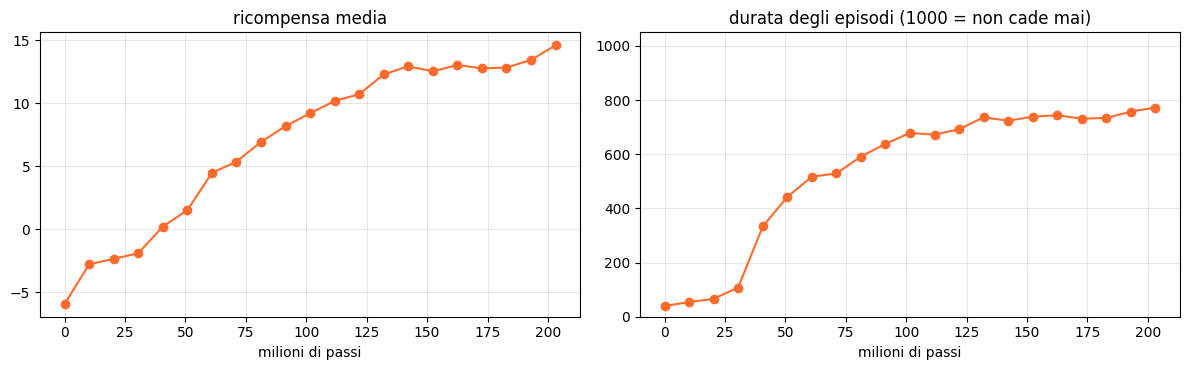

,step,eval_reward,eval_episode_length,minutes
16,162529280,13.034042,743.859375,32.66
17,172687360,12.764145,731.140625,34.47
18,182845440,12.834308,733.890625,36.29
19,193003520,13.433640,757.343750,38.10
20,203161600,14.601208,772.328125,39.91


In [13]:
import matplotlib.pyplot as plt
df = pd.read_csv(f"{OUT}/progress.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(df.step / 1e6, df.eval_reward, "o-", color="#FF6B2C"); ax[0].set_title("ricompensa media")
ax[1].plot(df.step / 1e6, df.eval_episode_length, "o-", color="#FF6B2C")
ax[1].set_title("durata degli episodi (1000 = non cade mai)"); ax[1].set_ylim(0, 1050)
for a in ax:
    a.set_xlabel("milioni di passi"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
df.tail()

## 11. Il robot addestrato cammina

Carichiamo la rete finale e le diamo un percorso di comandi, come se avessimo un joystick: fermo, avanti, curva, di lato, fermo. Usiamo l'**azione media** della rete (senza il campionamento casuale che serve solo per esplorare durante l'addestramento).

Se hai usato la modalità `prova` il robot cadrà subito: 2.000 passi non bastano a imparare nulla.

In [14]:
import json, pickle, glob
from brax.training.acme import running_statistics
from brax.training.agents.ppo import networks as ppo_networks

conf = json.load(open(f"{OUT}/network_config.json"))
reti = ppo_networks.make_ppo_networks(
    {k: tuple(v) if isinstance(v, list) else v for k, v in conf["obs_size"].items()},
    conf["action_size"],
    preprocess_observations_fn=running_statistics.normalize,
    **conf["network_factory_kwargs"])
crea_politica = ppo_networks.make_inference_fn(reti)

def carica(file_pkl):
    # Dai pesi salvati a una funzione oss -> azione (azione media, senza esplorazione)
    params = pickle.load(open(file_pkl, "rb"))
    inf = crea_politica(params, deterministic=True)
    return lambda oss, k: inf(oss, k)[0]

finale = carica(f"{OUT}/fasi/step_final.pkl")
giro = percorso([(1.0, [0, 0, 0]), (4.0, [0.8, 0, 0]), (3.0, [0.6, 0, 0.8]),
                 (3.0, [0, 0.4, 0]), (2.0, [-0.5, 0, 0]), (1.0, [0, 0, 0])])
video_finale = gira(finale, giro, seme=3)
media.show_video(video_finale, fps=1 / (env.dt * SALTA))

This browser does not support the video tag.


## 12. Com'è cambiato durante l'addestramento

Le "fotografie" della rete salvate a ogni valutazione ci permettono di rivedere **lo stesso percorso** con la rete di diversi momenti dell'addestramento: appena nata, a metà strada, alla fine.

In [15]:
fasi = sorted(glob.glob(f"{OUT}/fasi/step_0*.pkl"))
scelte = [fasi[0], fasi[len(fasi) // 2], f"{OUT}/fasi/step_final.pkl"]
breve = percorso([(1.0, [0, 0, 0]), (5.0, [0.8, 0, 0])])
video = {}
for f in scelte:
    nome = "finale" if f.endswith("final.pkl") else f"{int(os.path.basename(f)[5:17]) / 1e6:.0f} M passi"
    video[nome] = gira(carica(f), breve, seme=1)
media.show_videos(video, fps=1 / (env.dt * SALTA), height=240)

0 M passi This browser does not support the video tag.,102 M passi This browser does not support the video tag.,finale This browser does not support the video tag.


## 13. Portare la rete fuori da JAX (numpy puro)

La rete addestrata è piccola: **4 moltiplicazioni di matrici**. Con i file `.npz` la puoi eseguire ovunque ci sia numpy, per esempio sul tuo portatile insieme a MuJoCo (anche su un Mac senza GPU: noi l'abbiamo fatto per la demo dal vivo).

La cella ricostruisce la rete in numpy e controlla che dia **le stesse azioni** della versione JAX.

In [16]:
z = np.load(f"{OUT}/fasi/step_final.npz")
print("\n".join(f"{k:45s} {z[k].shape}" for k in z.files if k.startswith("[0].m") or k.startswith("[0].s") or k.startswith("[1]")))

def rete_numpy(oss_state):
    x = (oss_state - z["[0].mean['state']"]) / z["[0].std['state']"]       # normalizzazione
    for i in range(3):                                                     # 3 strati nascosti, swish
        x = x @ z[f"[1]['params']['hidden_{i}']['kernel']"] + z[f"[1]['params']['hidden_{i}']['bias']"]
        x = x / (1 + np.exp(-x))
    x = x @ z["[1]['params']['hidden_3']['kernel']"] + z["[1]['params']['hidden_3']['bias']"]
    return np.tanh(x[:env.action_size])                                    # azione media

s = env.reset(jax.random.PRNGKey(5))
a_jax = np.asarray(finale(s.obs, jax.random.PRNGKey(0)))
a_np = rete_numpy(np.asarray(s.obs["state"]))
print("\nDifferenza massima JAX vs numpy:", float(np.abs(a_jax - a_np).max()))

[0].mean['privileged_state']                  (216,)
[0].mean['state']                             (103,)
[0].std['privileged_state']                   (216,)
[0].std['state']                              (103,)
[0].summed_variance['privileged_state']       (216,)
[0].summed_variance['state']                  (103,)
[0].std_eps                                   ()
[1]['params']['hidden_0']['bias']             (512,)
[1]['params']['hidden_0']['kernel']           (103, 512)
[1]['params']['hidden_1']['bias']             (256,)
[1]['params']['hidden_1']['kernel']           (512, 256)
[1]['params']['hidden_2']['bias']             (128,)
[1]['params']['hidden_2']['kernel']           (256, 128)
[1]['params']['hidden_3']['bias']             (58,)
[1]['params']['hidden_3']['kernel']           (128, 58)

Differenza massima JAX vs numpy: 1.9371509552001953e-07


Nel repository del progetto, la cartella [`simulatore/`](https://github.com/StefanoCapezzone/cadi-rialzati-cammina/tree/main/simulatore) fa esattamente questo: un visualizzatore MuJoCo da tastiera (Linux e Mac, anche senza GPU) con la nostra rete già addestrata.

Per farlo da soli servono: il modello del robot di Playground (`env.mj_model`, da salvare con `mujoco.mj_saveLastXML` o copiando gli XML da `mujoco_playground/_src/locomotion/g1/xmls` più le mesh di MuJoCo Menagerie), la costruzione dei 103 ingressi descritta nella sezione 4 e il passo di controllo: `ctrl = posa + 0,5 × azione`, tenuto per 10 passi di fisica da 2 ms.

In [17]:
# Scarica pesi e curve in un unico zip (su Colab parte il download nel browser)
import shutil
zip_ = shutil.make_archive("g1_tutorial_risultati", "zip", OUT)
print("Creato", zip_)
try:
    from google.colab import files
    files.download(zip_)
except ImportError:
    pass

Creato /content/g1_tutorial_risultati.zip


## 14. Esperimenti da provare

Lo script accetta `--set CHIAVE=VALORE` per cambiare la configurazione dell'ambiente, e `--no_dr` per togliere la domain randomization. Usa una cartella diversa per ogni esperimento e confronta le curve. Qualche idea:

| esperimento | comando | cosa aspettarsi (da verificare!) |
|---|---|---|
| niente premio per i passi veri | `--set reward_config.scales.feet_air_time=0` | rischio di passi strisciati o saltelli |
| niente penalità per la caduta | `--set reward_config.scales.termination=0` | impara più lentamente a stare in piedi? |
| busto libero | `--set reward_config.scales.orientation=0` | posture strane: *reward hacking* in agguato |
| mondo perfetto | `--no_dr` | in simulazione forse va anche meglio... ma su un robot vero? |
| meno robot in parallelo | `--num_envs 2048` | più lento, curve più rumorose |

Esempio (in una nuova cella):
```
!python -u addestra_g1.py --out g1_senza_passi --passi 50000000 --valutazioni 11 --impl warp \
    --set reward_config.scales.feet_air_time=0 2>&1 | grep --line-buffered -E "^\[|Fatto|Error"
```
Poi rifai le sezioni 10-12 con `OUT = "g1_senza_passi"`.

**Domanda da tenere a mente:** il robot ottimizza quello che chiedi, non quello che intendi. Prima di guardare il video, prova a indovinare cosa farà.

## 15. Per approfondire

**Articoli** (tutti liberi su arXiv)
- J. Schulman et al., *Proximal Policy Optimization Algorithms*, 2017 — [arXiv:1707.06347](https://arxiv.org/abs/1707.06347)
- J. Schulman et al., *High-Dimensional Continuous Control Using Generalized Advantage Estimation*, ICLR 2016 — [arXiv:1506.02438](https://arxiv.org/abs/1506.02438)
- S. Huang et al., *The 37 Implementation Details of Proximal Policy Optimization*, ICLR Blog Track 2022
- L. Pinto et al., *Asymmetric Actor Critic for Image-Based Robot Learning*, 2017 — [arXiv:1710.06542](https://arxiv.org/abs/1710.06542)
- J. Tobin et al., *Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World*, 2017 — [arXiv:1703.06907](https://arxiv.org/abs/1703.06907)
- N. Rudin et al., *Learning to Walk in Minutes Using Massively Parallel Deep Reinforcement Learning*, CoRL 2021 — [arXiv:2109.11978](https://arxiv.org/abs/2109.11978)
- C. D. Freeman et al., *Brax — A Differentiable Physics Engine for Large Scale Rigid Body Simulation*, 2021 — [arXiv:2106.13281](https://arxiv.org/abs/2106.13281)
- K. Zakka et al., *MuJoCo Playground*, RSS 2025 — [arXiv:2502.08844](https://arxiv.org/abs/2502.08844)

**Questo progetto:** https://github.com/StefanoCapezzone/cadi-rialzati-cammina (slide, video, visualizzatore, tutti gli script)

**Codice e corsi**
- MuJoCo Playground: https://github.com/google-deepmind/mujoco_playground · https://playground.mujoco.org
- Brax: https://github.com/google/brax · MuJoCo: https://mujoco.org
- OpenAI Spinning Up, PPO: https://spinningup.openai.com
- Hugging Face Deep RL Course: https://huggingface.co/learn/deep-rl-course

**Limiti, detti chiaramente:** questa rete non l'abbiamo mai provata su un G1 vero. Passare dalla simulazione alla realtà (*sim-to-real*) è la parte più difficile, ed è il motivo della domain randomization e del rumore sui sensori.

---
*Cadi, rialzati, cammina* — Linux Day 2026, Roma2LUG. Contatti: stefano@capezzone.it